# Máquinas de Soporte Vectorial (SVM) para clasificar dígitos manuscritos

**Integrantes:** Juan Diego Palacios & Andrea de la Ossa

**Plan del cuaderno**

1. Librerías y datos
2. Partición 80/20 y validación cruzada (misma que en el Taller 9)
3. Fundamento: qué es una SVM y qué hace cada kernel
4. Efecto del preprocesamiento (escalado) en cada kernel
5. Búsqueda de hiperparámetros por kernel con k-fold
6. Elección del mejor kernel
7. Evaluación final en el conjunto de prueba
8. Comparación con los Talleres 9 y 10
9. Conclusiones

## 1. Librerías y configuración

In [ ]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 2. Los datos

`load_digits` contiene **1797 imágenes de 8×8 píxeles** (64 atributos) de dígitos manuscritos. Cada píxel es un entero de **0 a 16** (intensidad de tinta) y hay **10 clases** (0–9) casi balanceadas.

Forma de X: (1797, 64) | Forma de y: (1797,)
Rango de los píxeles: 0.0 a 16.0

Ejemplos por clase: [178 182 177 183 181 182 181 179 174 180]


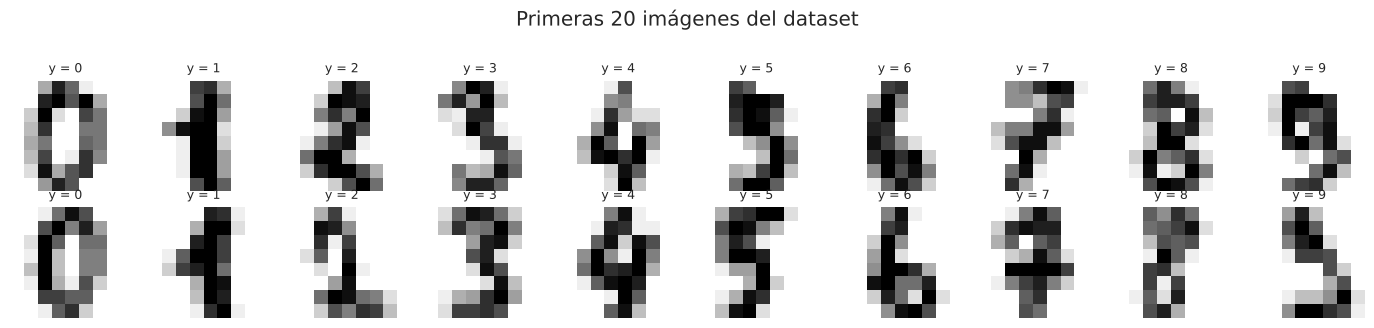

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("Rango de los píxeles:", X.min(), "a", X.max())
print("\nEjemplos por clase:", np.bincount(y))

fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, img, lab in zip(axes.ravel(), digits.images[:20], y[:20]):
    ax.imshow(img, cmap="gray_r"); ax.set_title(f"y = {lab}", fontsize=9); ax.axis("off")
plt.suptitle("Primeras 20 imágenes del dataset", y=1.02); plt.tight_layout(); plt.show()

## 3. Partición 80 / 20 y validación cruzada (K = 4)

Para que la comparación con los talleres anteriores sea **justa**, se usa exactamente el mismo protocolo del Taller 9:

* **80 % entrenamiento / 20 % prueba**, estratificado y con `random_state=42`.
* Toda la selección (kernel e hiperparámetros) se hace **solo con el 80 %**, mediante `StratifiedKFold(n_splits=4)`. Las métricas de cada modelo son el **promedio de los 4 folds** (precisión, exhaustividad y F1 con promedio *macro* entre las 10 clases).
* El 20 % de prueba se usa **una sola vez, al final**.

Además se verifica que este conjunto de prueba es **idéntico** al del Taller 9 y al del Taller 10 (ambos usaron la misma semilla y estratificación), de modo que las cifras de prueba son directamente comparables.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)

# Verificación: el conjunto de prueba coincide con el del Taller 10 (que parte índices en lugar de X, y)
idx = np.arange(len(y))
_, i_test_t10 = train_test_split(idx, test_size=0.20, stratify=y, random_state=SEED)
print("¿Misma partición de prueba que los talleres 9 y 10?:", np.array_equal(X[i_test_t10], X_test))

print(f"Entrenamiento: {len(X_train)} imágenes | Prueba: {len(X_test)} imágenes")
for i, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    print(f"  Fold {i}: {len(tr)} para ajustar / {len(va)} para validar")

SCORING = {"accuracy": "accuracy", "precision": "precision_macro",
           "recall": "recall_macro", "f1": "f1_macro"}

def cv_metrics(modelo):
    """Promedio de las 4 particiones de cada métrica (+ desviación de la exactitud y tiempo de ajuste)."""
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=SCORING)
    out = {k: r[f"test_{k}"].mean() for k in SCORING}
    out["std_exactitud"] = r["test_accuracy"].std()
    out["seg_ajuste"] = r["fit_time"].mean()
    return out

¿Misma partición de prueba que los talleres 9 y 10?: True
Entrenamiento: 1437 imágenes | Prueba: 360 imágenes
  Fold 1: 1077 para ajustar / 360 para validar
  Fold 2: 1078 para ajustar / 359 para validar
  Fold 3: 1078 para ajustar / 359 para validar
  Fold 4: 1078 para ajustar / 359 para validar


## 4. Fundamento: la SVM y sus kernels

Una SVM busca el **hiperplano de máxima margen** que separa dos clases. Para 10 clases, `SVC` entrena clasificadores **uno-contra-uno** (45 SVM binarias) y decide por votación.

Cuando los datos no son separables linealmente, se usa el **truco del kernel**: la SVM trabaja con $K(\mathbf{x},\mathbf{x}')=\phi(\mathbf{x})\cdot\phi(\mathbf{x}')$, que equivale a un producto punto en un espacio de dimensión mayor sin calcular $\phi$ explícitamente.

| Kernel | Fórmula $K(\mathbf{x},\mathbf{x}')$ | Frontera de decisión | Hiperparámetros |
|---|---|---|---|
| **linear** | $\mathbf{x}\cdot\mathbf{x}'$ | hiperplano | $C$ |
| **poly** | $(\gamma\,\mathbf{x}\cdot\mathbf{x}'+r)^d$ | polinomio de grado $d$ | $C,\ d,\ \gamma,\ r$ |
| **rbf** | $\exp(-\gamma\|\mathbf{x}-\mathbf{x}'\|^2)$ | superficies suaves y locales | $C,\ \gamma$ |
| **sigmoid** | $\tanh(\gamma\,\mathbf{x}\cdot\mathbf{x}'+r)$ | similar a una red de 2 capas | $C,\ \gamma,\ r$ |

* **$C$** (regularización): $C$ pequeño → margen ancho, tolera errores (más sesgo, menos varianza); $C$ grande → penaliza fuertemente los errores de entrenamiento (riesgo de sobreajuste).
* **$\gamma$**: qué tan lejos llega la influencia de un ejemplo de entrenamiento. $\gamma$ grande → frontera muy local y compleja; $\gamma$ pequeño → frontera suave. `gamma="scale"` usa $1/(n_{\text{atributos}}\cdot \text{Var}(X))$.

## 5. Efecto del preprocesamiento (escalado) en cada kernel

Las SVM con kernels `poly`, `rbf` y `sigmoid` dependen de **distancias o productos punto**, así que la escala de los atributos importa. En `digits` todos los píxeles ya están en la misma escala (0–16), por lo que *no es obvio* que estandarizar ayude: `StandardScaler` divide cada píxel por su desviación estándar y, en los píxeles casi siempre en 0 (los bordes), esa desviación es diminuta, así que **amplifica ruido**.

En lugar de suponer, se mide: cada kernel con sus hiperparámetros por defecto, **con y sin** `StandardScaler`, con K = 4.

"F1 macro (CV, hiperparámetros por defecto)",crudo (0–16),estandarizado
kernel,,
linear,0.9754,0.9754
poly,0.9888,0.9482
rbf,0.9881,0.9811
sigmoid,0.9063,0.9432


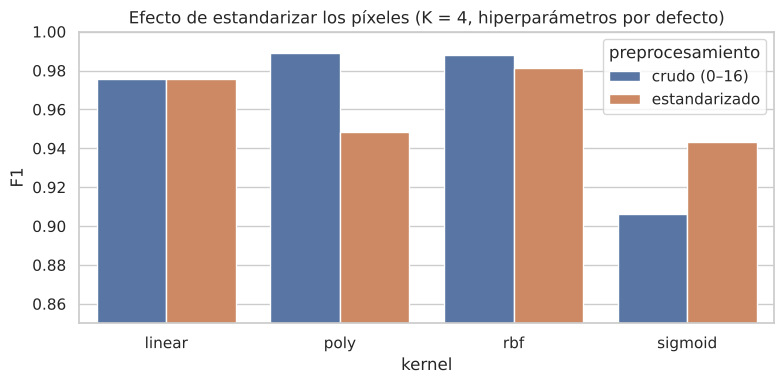

In [ ]:
KERNELS = ["linear", "poly", "rbf", "sigmoid"]

def pipe(kernel, escalar):
    paso = StandardScaler() if escalar else "passthrough"
    return Pipeline([("escala", paso), ("svc", SVC(kernel=kernel))])

filas = []
for k in KERNELS:
    for esc in [False, True]:
        m = cv_metrics(pipe(k, esc))
        filas.append({"kernel": k, "preprocesamiento": "estandarizado" if esc else "crudo (0–16)",
                      "Exactitud": m["accuracy"], "F1": m["f1"], "Desv. exactitud": m["std_exactitud"]})
tabla_esc = pd.DataFrame(filas)
display(tabla_esc.pivot(index="kernel", columns="preprocesamiento", values="F1").loc[KERNELS].round(4)
        .rename_axis(columns="F1 macro (CV, hiperparámetros por defecto)"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=tabla_esc, x="kernel", y="F1", hue="preprocesamiento", ax=ax)
ax.set_ylim(0.85, 1.0); ax.set_title("Efecto de estandarizar los píxeles (K = 4, hiperparámetros por defecto)")
plt.tight_layout(); plt.show()

**Lectura.** Con los hiperparámetros por defecto, estandarizar **empeora** de forma apreciable a los kernels `poly` y `rbf` (y `sigmoid`), y es neutro para `linear`. Por eso el escalado **no se fija de antemano**: se trata como un hiperparámetro más y se deja que la validación cruzada decida, kernel por kernel.

## 6. Búsqueda de hiperparámetros por kernel (K-fold)

Para cada kernel se hace una búsqueda exhaustiva (`GridSearchCV`, K = 4, métrica **F1 macro**) sobre su rejilla de hiperparámetros **y** sobre el preprocesamiento (crudo vs. estandarizado). Así cada kernel compite en su **mejor versión**, no con valores arbitrarios. Todo ocurre únicamente dentro del conjunto de entrenamiento.

In [ ]:
ESCALAS = ["passthrough", StandardScaler()]
rejillas = {
    "linear":  {"escala": ESCALAS, "svc__C": [1e-5, 1e-4, 0.001, 0.01, 0.1, 1, 10, 100]},
    "poly":    {"escala": ESCALAS, "svc__C": [0.001, 0.01, 0.1, 1, 10, 100], "svc__degree": [2, 3, 4],
                "svc__gamma": ["scale", 1e-4, 1e-3, 1e-2]},
    "rbf":     {"escala": ESCALAS, "svc__C": [0.1, 1, 10, 100, 1000],
                "svc__gamma": ["scale", 1e-4, 1e-3, 1e-2, 1e-1]},
    "sigmoid": {"escala": ESCALAS, "svc__C": [0.1, 1, 10, 100, 1000],
                "svc__gamma": ["scale", 1e-4, 1e-3, 1e-2], "svc__coef0": [0, 1]},
}

busquedas, mejores = {}, []
for k in KERNELS:
    t0 = time.perf_counter()
    gs = GridSearchCV(Pipeline([("escala", "passthrough"), ("svc", SVC(kernel=k))]),
                      rejillas[k], scoring="f1_macro", cv=cv, refit=True, n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[k] = gs
    m = cv_metrics(gs.best_estimator_)                  # las 4 métricas promedio con los mismos 4 folds
    p = {n.replace("svc__", ""): v for n, v in gs.best_params_.items() if n != "escala"}
    esc = "estandarizado" if not isinstance(gs.best_params_["escala"], str) else "crudo"
    mejores.append({"kernel": k, "Exactitud": m["accuracy"], "Precisión": m["precision"],
                    "Exhaustividad": m["recall"], "F1": m["f1"], "Desv. exactitud": m["std_exactitud"],
                    "preprocesamiento": esc, "mejores hiperparámetros": p,
                    "combinaciones": len(gs.cv_results_["params"]), "búsqueda (s)": time.perf_counter() - t0})

resumen = pd.DataFrame(mejores).set_index("kernel")
display(resumen.sort_values("F1", ascending=False).round(4))

,Exactitud,Precisión,Exhaustividad,F1,Desv. exactitud,preprocesamiento,mejores hiperparámetros,combinaciones,búsqueda (s)
kernel,,,,,,,,,
rbf,0.9903,0.9905,0.9902,0.9903,0.0031,crudo,"{'C': 10, 'gamma': 'scale'}",50,11.4094
poly,0.9896,0.9899,0.9896,0.9896,0.0023,crudo,"{'C': 0.1, 'degree': 3, 'gamma': 0.001}",144,23.3463
linear,0.9791,0.9798,0.9789,0.9790,0.0050,crudo,{'C': 0.001},16,1.7895
sigmoid,0.9777,0.9786,0.9776,0.9777,0.0040,estandarizado,"{'C': 100, 'coef0': 0, 'gamma': 0.001}",80,20.2545


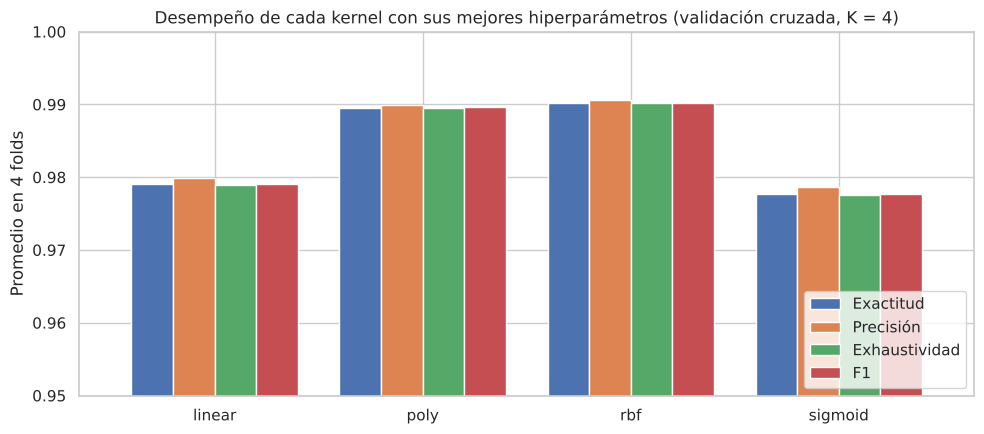

In [ ]:
met = ["Exactitud", "Precisión", "Exhaustividad", "F1"]
ax = resumen[met].loc[KERNELS].plot.bar(figsize=(10, 4.5), width=0.8)
ax.set_ylim(0.95, 1.0); ax.set_ylabel("Promedio en 4 folds"); ax.set_xlabel("")
ax.set_title("Desempeño de cada kernel con sus mejores hiperparámetros (validación cruzada, K = 4)")
plt.xticks(rotation=0); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 6.1. Sensibilidad a $C$ y $\gamma$ en el kernel RBF
Mapa de calor del F1 medio (K = 4) para el kernel RBF, con los datos crudos y con los estandarizados, para ver qué región de hiperparámetros funciona.

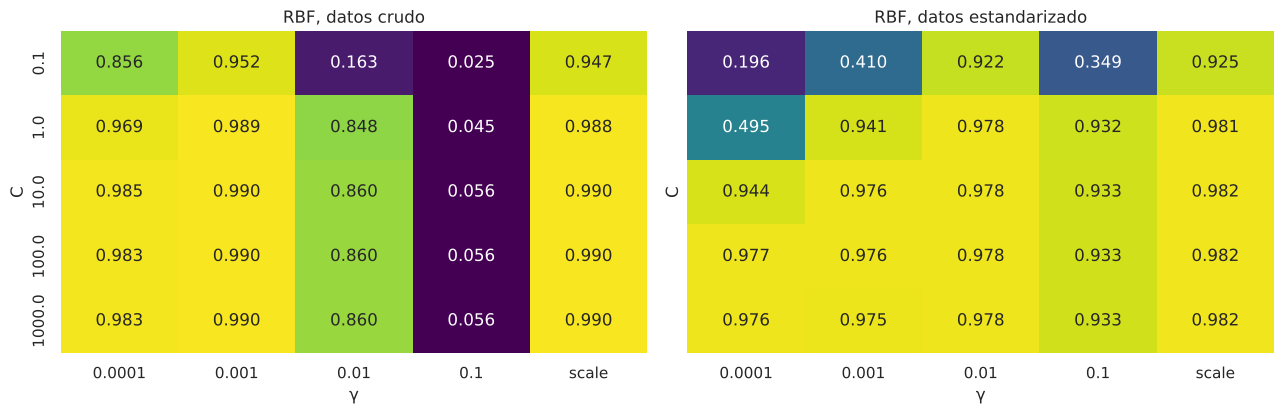

In [ ]:
res = pd.DataFrame(busquedas["rbf"].cv_results_)
res["prep"] = res["param_escala"].apply(lambda v: "crudo" if isinstance(v, str) else "estandarizado")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, prep in zip(axes, ["crudo", "estandarizado"]):
    sub = res[res["prep"] == prep]
    piv = sub.pivot_table(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score", aggfunc="max")
    sns.heatmap(piv.astype(float), annot=True, fmt=".3f", cmap="viridis", vmin=0.1, vmax=1, ax=ax, cbar=False)
    ax.set_title(f"RBF, datos {prep}"); ax.set_xlabel("γ"); ax.set_ylabel("C")
plt.tight_layout(); plt.show()

## 7. Elección del mejor kernel

In [ ]:
orden = resumen.sort_values("F1", ascending=False)
mejor_k = orden.index[0]
print("Ranking por F1 macro (promedio de 4 folds):")
for k, r in orden.iterrows():
    print(f"  {k:8s}  F1 = {r['F1']:.4f}  exactitud = {r['Exactitud']:.4f} ± {r['Desv. exactitud']:.4f}  | {r['preprocesamiento']}, {r['mejores hiperparámetros']}")

# ¿La diferencia entre los dos primeros es relevante? Se compara fold por fold con los mismos folds.
a, b = orden.index[0], orden.index[1]
fa = cross_validate(busquedas[a].best_estimator_, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
fb = cross_validate(busquedas[b].best_estimator_, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
print(f"\nExactitud por fold: {a} = {np.round(fa, 4)} | {b} = {np.round(fb, 4)}")
print(f"Diferencia media {a} − {b}: {100*(fa-fb).mean():.2f} puntos porcentuales "
      f"(desviación entre folds de la diferencia: {100*(fa-fb).std():.2f})")
print("Mejor kernel según K-fold:", mejor_k)

Ranking por F1 macro (promedio de 4 folds):
  rbf       F1 = 0.9903  exactitud = 0.9903 ± 0.0031  | crudo, {'C': 10, 'gamma': 'scale'}
  poly      F1 = 0.9896  exactitud = 0.9896 ± 0.0023  | crudo, {'C': 0.1, 'degree': 3, 'gamma': 0.001}
  linear    F1 = 0.9790  exactitud = 0.9791 ± 0.0050  | crudo, {'C': 0.001}
  sigmoid   F1 = 0.9777  exactitud = 0.9777 ± 0.0040  | estandarizado, {'C': 100, 'coef0': 0, 'gamma': 0.001}

Exactitud por fold: rbf = [0.9889 0.9861 0.9916 0.9944] | poly = [0.9889 0.9861 0.9916 0.9916]
Diferencia media rbf − poly: 0.07 puntos porcentuales (desviación entre folds de la diferencia: 0.12)
Mejor kernel según K-fold: rbf


**Lectura de los resultados**

* **`rbf` obtiene el mayor desempeño promedio en K-fold** (F1 ≈ 0,990, exactitud ≈ 99,0 %), seguido muy de cerca por `poly` (≈ 0,990). Ambos superan con claridad a `linear` (≈ 0,979) y `sigmoid` (≈ 0,978).
* **La diferencia entre `rbf` y `poly` no es concluyente:** es de ≈ 0,07 puntos porcentuales, menor que la desviación entre folds (≈ 0,3 pp). Se elige `rbf` porque es el primero del ranking y porque es más robusto: funciona bien con el valor por defecto `gamma="scale"` (γ ≈ 0,0004 con estos datos), mientras que `poly` necesita un $C$ y un $\gamma$ muy pequeños y de más hiperparámetros (grado, $\gamma$, $r$) para llegar al mismo punto.
* **`linear` ya es muy bueno (≈ 97,9 %)**: los dígitos son casi linealmente separables en 64 dimensiones. Con datos crudos el mejor $C$ es muy pequeño (0,001): un margen ancho y muy regularizado generaliza mejor.
* **`sigmoid` es el más débil y el más delicado.** Con valores por defecto llega solo a ≈ 0,91 con datos crudos; necesita estandarizar y ajustar $C$ y $\gamma$ para alcanzar ≈ 0,978. Además no es un kernel semidefinido positivo para todos los parámetros, lo que explica su comportamiento menos estable.
* **El escalado importa, y no siempre en el sentido esperado.** Para `rbf`, `poly` y `linear` los datos **crudos (0–16)** superan a los estandarizados (la estandarización amplifica el ruido de los píxeles de borde, casi siempre 0). Solo `sigmoid` se beneficia de estandarizar.
* **Sensibilidad a los hiperparámetros (mapa de calor):** en `rbf` con datos crudos, $\gamma \in [10^{-4}, 10^{-3}]$ o `scale` funcionan bien para $C \ge 1$. Con $\gamma = 0{,}1$ el modelo **colapsa a nivel de azar** (F1 ≈ 0,06): cada ejemplo influye solo sobre sí mismo (sobreajuste extremo, el modelo memoriza). Con $C$ muy pequeño (0,1) sobra regularización y el modelo subajusta.
* **Robustez de la búsqueda:** los óptimos de `linear` y `poly` aparecieron primero en el borde de la rejilla; se amplió el rango ($C$ hasta $10^{-5}$ en `linear`, hasta $10^{-3}$ en `poly`, $\gamma$ hasta $10^{-4}$) y el mejor valor siguió siendo el mismo, ahora en el interior. Es decir, no había una mejor configuración fuera de la rejilla original.

## 8. Evaluación final en el conjunto de prueba

El modelo elegido ya está reentrenado con todo el 80 % (`refit=True`). Se evalúa **una vez** en el 20 % de prueba. Por transparencia se reportan también los otros kernels (solo informativo; **no** se usaron para elegir).

In [ ]:
modelo_final = busquedas[mejor_k].best_estimator_
y_pred = modelo_final.predict(X_test)

print(f"=== Mejor kernel: {mejor_k} | {resumen.loc[mejor_k, 'preprocesamiento']} | {resumen.loc[mejor_k, 'mejores hiperparámetros']} ===")
print(f"Exactitud:             {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisión (macro):     {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Exhaustividad (macro): {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 (macro):            {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, digits=4))

filas = {}
for k in KERNELS:
    yp = busquedas[k].best_estimator_.predict(X_test)
    filas[k + ("  <- elegido" if k == mejor_k else "")] = {
        "Exactitud": accuracy_score(y_test, yp), "Precisión": precision_score(y_test, yp, average="macro"),
        "Exhaustividad": recall_score(y_test, yp, average="macro"), "F1": f1_score(y_test, yp, average="macro"),
        "Errores (de 360)": int((yp != y_test).sum())}
print("Todos los kernels en PRUEBA (informativo):")
display(pd.DataFrame(filas).T.round(4))

=== Mejor kernel: rbf | crudo | {'C': 10, 'gamma': 'scale'} ===
Exactitud:             0.9944
Precisión (macro):     0.9946
Exhaustividad (macro): 0.9944
F1 (macro):            0.9944

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        36
           1     0.9730    1.0000    0.9863        36
           2     1.0000    1.0000    1.0000        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    1.0000    1.0000        36
           7     0.9730    1.0000    0.9863        36
           8     1.0000    0.9714    0.9855        35
           9     1.0000    0.9722    0.9859        36

    accuracy                         0.9944       360
   macro avg     0.9946    0.9944    0.9944       360
weighted avg     0.9946    0.9944    0.9944       360

Todos los kernels en PRUEBA (informativo):


,Exactitud,Precisión,Exhaustividad,F1,Errores (de 360)
linear,0.9861,0.9866,0.9860,0.9861,5.0
poly,0.9861,0.9864,0.9860,0.9860,5.0
rbf <- elegido,0.9944,0.9946,0.9944,0.9944,2.0
sigmoid,0.9833,0.9834,0.9831,0.9831,6.0


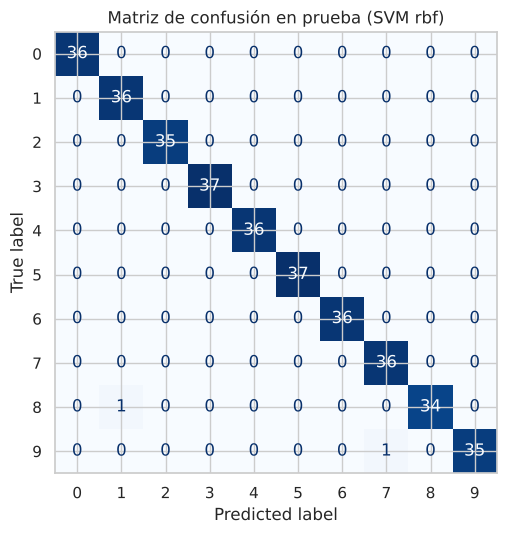

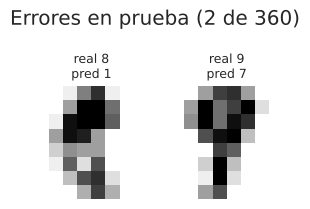

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión en prueba (SVM {mejor_k})"); plt.tight_layout(); plt.show()

err = np.where(y_pred != y_test)[0]
n = max(1, min(10, len(err)))
fig, axes = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
for a_, i in zip(np.atleast_1d(axes), err[:n]):
    a_.imshow(X_test[i].reshape(8, 8), cmap="gray_r"); a_.axis("off")
    a_.set_title(f"real {y_test[i]}\npred {y_pred[i]}", fontsize=9)
plt.suptitle(f"Errores en prueba ({len(err)} de {len(y_test)})", y=1.1); plt.show()

## 9. Comparación con los Talleres 9 y 10

Para comparar con rigor, los modelos de los talleres anteriores se **reconstruyen aquí con sus configuraciones elegidas** y se evalúan con el **mismo protocolo** (mismo 80 % de entrenamiento, mismos 4 folds y mismos 360 dígitos de prueba):

* **Taller 9 – Naïve Bayes:** `MultinomialNB` (el mejor tipo de NB del taller). Se incluye α = 1 y α = 100, el valor que eligió su `GridSearchCV`.
* **Taller 10 – MLP:** una capa oculta de 64 neuronas, solver L-BFGS, `StandardScaler`; activación `tanh` (la elegida por el taller) y `relu` (la otra candidata).

Nota: el Taller 10 entrenó con el 60 % de los datos y validó con otro 20 %; aquí el MLP se entrena con el 80 %, igual que los otros modelos, para no darle desventaja ni ventaja a ninguno.

In [ ]:
def mlp(act):
    return Pipeline([("escala", StandardScaler()),
                     ("mlp", MLPClassifier(hidden_layer_sizes=(64,), activation=act, solver="lbfgs",
                                           alpha=1e-4, tol=1e-6, max_iter=2000, max_fun=50000, random_state=SEED))])

comparados = {
    "Taller 9 · MultinomialNB (α=1)":   MultinomialNB(alpha=1.0),
    "Taller 9 · MultinomialNB (α=100)": MultinomialNB(alpha=100.0),
    "Taller 10 · MLP tanh":             mlp("tanh"),
    "Taller 10 · MLP relu":             mlp("relu"),
    f"Taller 11 · SVM {mejor_k} (mejor)": busquedas[mejor_k].best_estimator_,
}
# Para completar la comparación también se incluye el mejor SVM de cada uno de los otros kernels
for k in KERNELS:
    if k != mejor_k:
        comparados[f"Taller 11 · SVM {k}"] = busquedas[k].best_estimator_

filas = []
for nombre, modelo in comparados.items():
    m = cv_metrics(modelo)
    t0 = time.perf_counter(); modelo.fit(X_train, y_train); t_fit = time.perf_counter() - t0
    yp = modelo.predict(X_test)
    filas.append({"Modelo": nombre,
                  "CV Exactitud": m["accuracy"], "CV Precisión": m["precision"],
                  "CV Exhaustividad": m["recall"], "CV F1": m["f1"], "CV Desv. exactitud": m["std_exactitud"],
                  "Prueba Exactitud": accuracy_score(y_test, yp), "Prueba F1": f1_score(y_test, yp, average="macro"),
                  "Errores en prueba": int((yp != y_test).sum()), "Tiempo de ajuste (s)": t_fit})
comp = pd.DataFrame(filas).set_index("Modelo")
display(comp.sort_values("CV F1", ascending=False).round(4))

,CV Exactitud,CV Precisión,CV Exhaustividad,CV F1,CV Desv. exactitud,Prueba Exactitud,Prueba F1,Errores en prueba,Tiempo de ajuste (s)
Modelo,,,,,,,,,
Taller 11 · SVM rbf (mejor),0.9903,0.9905,0.9902,0.9903,0.0031,0.9944,0.9944,2,0.0393
Taller 11 · SVM poly,0.9896,0.9899,0.9896,0.9896,0.0023,0.9861,0.9860,5,0.0164
Taller 11 · SVM linear,0.9791,0.9798,0.9789,0.9790,0.0050,0.9861,0.9861,5,0.0161
Taller 11 · SVM sigmoid,0.9777,0.9786,0.9776,0.9777,0.0040,0.9833,0.9831,6,0.0248
Taller 10 · MLP relu,0.9701,0.9710,0.9700,0.9700,0.0030,0.9806,0.9804,7,0.0559
Taller 10 · MLP tanh,0.9694,0.9700,0.9692,0.9692,0.0039,0.9694,0.9691,11,0.0448
Taller 9 · MultinomialNB (α=100),0.9074,0.9126,0.9075,0.9074,0.0084,0.8833,0.8809,42,0.0012
Taller 9 · MultinomialNB (α=1),0.9047,0.9121,0.9048,0.9050,0.0114,0.8889,0.8871,40,0.0013


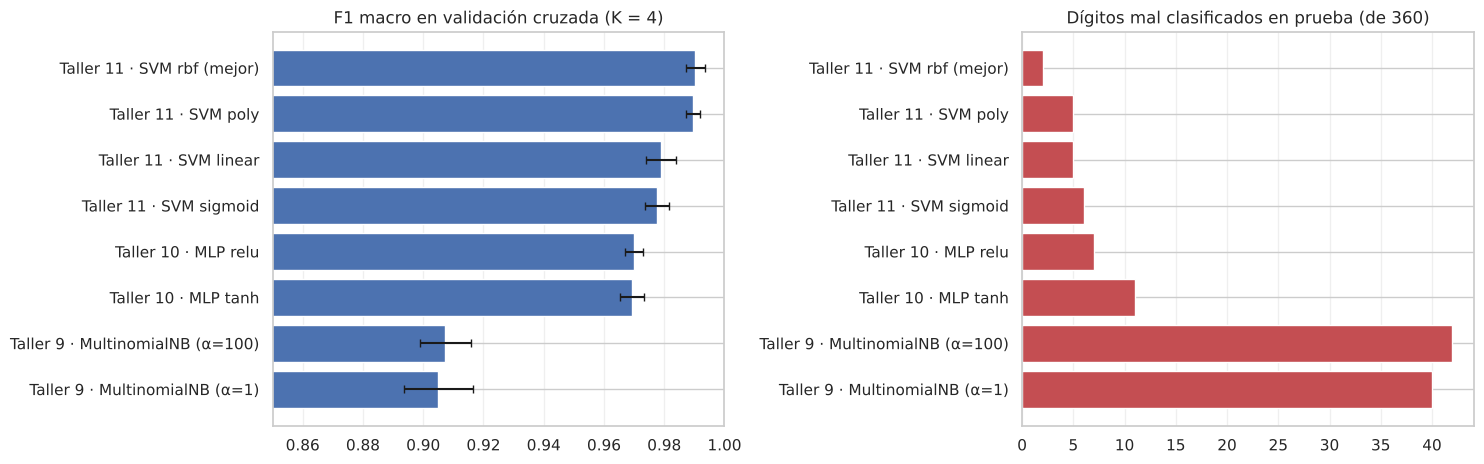

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
o = comp.sort_values("CV F1")
ax[0].barh(o.index, o["CV F1"], xerr=o["CV Desv. exactitud"], color="#4C72B0", capsize=3)
ax[0].set_xlim(0.85, 1.0); ax[0].set_title("F1 macro en validación cruzada (K = 4)")
ax[1].barh(o.index, o["Errores en prueba"], color="#C44E52")
ax[1].set_title("Dígitos mal clasificados en prueba (de 360)")
for a in ax: a.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

### 9.1. Qué se observa

* **El orden es claro y consistente tanto en validación cruzada como en prueba:** SVM (rbf) > MLP > Naïve Bayes. Las cifras de los Talleres 9 y 10 reproducidas aquí coinciden con lo que ellos reportaron: Naïve Bayes ≈ 88–90 % y MLP ≈ 96–98 %.
* **SVM frente a Naïve Bayes (Taller 9):** la mejora es enorme, de ≈ 90 % a ≈ 99 % en validación cruzada, y de ≈ 40 errores a 2 en los mismos 360 dígitos de prueba. Naïve Bayes supone **independencia entre píxeles**, algo claramente falso en imágenes, donde los píxeles vecinos están muy correlacionados. La SVM con kernel RBF compara imágenes completas y no necesita ese supuesto. Además, NB tiene mucha más variabilidad entre folds (desviación ≈ 0,008–0,011 vs. ≈ 0,003 de la SVM).
* **SVM frente al MLP (Taller 10):** la SVM también gana, pero por un margen mucho menor: ≈ 99,0 % frente a ≈ 97,0 % en K-fold (una diferencia de unos 2 puntos, mayor que la desviación entre folds de ≈ 0,3 pp) y 2 errores frente a 7 (`relu`) o 11 (`tanh`) en prueba. Con solo 1437 imágenes de entrenamiento, la SVM (que maximiza el margen y tiene solo dos hiperparámetros relevantes) generaliza mejor que una red con ≈ 4 800 parámetros que llega al 100 % en entrenamiento y sobreajusta ligeramente.
* **Costo computacional:** todos los modelos entrenan en fracciones de segundo en este conjunto tan pequeño (Naïve Bayes ≈ 1 ms, SVM ≈ 20 ms, MLP ≈ 50 ms). Naïve Bayes es el más rápido por mucho, pero la diferencia absoluta es irrelevante aquí; la SVM no es más costosa que el MLP. Con conjuntos mucho más grandes la SVM con kernel escalaría peor que una red (su costo crece entre cuadrático y cúbico con el número de ejemplos).

### 9.2. Salvedades honestas

* **La comparación favorece algo a la SVM:** su kernel e hiperparámetros se eligieron con una búsqueda de cientos de combinaciones, mientras que el MLP y Naïve Bayes se usan con las configuraciones que eligieron los talleres anteriores (sin reoptimizar con 80 % de datos). Un MLP más ajustado (más neuronas, regularización, *early stopping*) probablemente acortaría la distancia.
* **La métrica de validación cruzada del ganador está ligeramente inflada:** se eligió el máximo entre muchas configuraciones con esos mismos folds. Por eso las cifras de **prueba** son la estimación más honesta, y confirman el mismo orden.
* **El conjunto de prueba es pequeño (360 imágenes):** un solo dígito equivale a 0,28 puntos porcentuales. Que `rbf` falle 2 y `poly` o `linear` fallen 5 son diferencias de 3 imágenes, **no** evidencia sólida de que `rbf` sea mejor que `poly`. Sí es sólida la brecha respecto de Naïve Bayes (≈ 40 errores) y razonablemente sólida la del MLP.

## 10. Conclusiones

1. **Diseño:** se implementó una SVM (`SVC`, estrategia uno-contra-uno) para clasificar los 10 dígitos de `load_digits`, con partición estratificada 80/20 y validación cruzada de K = 4 sobre el entrenamiento; el conjunto de prueba se usó una sola vez, al final, y es el mismo que usaron los Talleres 9 y 10.
2. **Mejor kernel: RBF** (datos crudos, $C = 10$, $\gamma$ = `scale` ≈ 0,0004). Obtuvo en el promedio de los 4 folds exactitud ≈ 99,0 %, precisión ≈ 99,1 %, exhaustividad ≈ 99,0 % y F1 ≈ 99,0 %, y en prueba una exactitud de 99,4 % (2 errores de 360). El kernel `poly` quedó prácticamente empatado (la diferencia está dentro de la variación entre folds); `linear` y `sigmoid` quedaron algo por debajo (≈ 98 %).
3. **Hallazgos sobre los hiperparámetros:** estandarizar los píxeles **empeora** los kernels RBF y polinomial (en `digits` ya comparten escala y la estandarización amplifica el ruido en los píxeles casi constantes); $\gamma$ demasiado grande hace colapsar al modelo a nivel de azar, y $C$ demasiado pequeño lo subajusta.
4. **Comparación con los talleres anteriores:** SVM (RBF) ≈ 99 % > MLP ≈ 97 % > Naïve Bayes ≈ 90 % en validación cruzada, con el mismo orden en prueba (2, 7–11 y ≈ 40 errores, respectivamente). La mejora sobre Naïve Bayes es muy grande porque la SVM no requiere el supuesto de independencia entre píxeles; la mejora sobre el MLP es menor, pero consistente.
5. **Limitaciones:** una sola partición 80/20 y un conjunto de prueba de 360 imágenes (un dígito = 0,28 pp); SVM tuvo una búsqueda de hiperparámetros más extensa que los otros dos modelos; y las diferencias entre `rbf` y `poly` no son estadísticamente concluyentes. Para afirmar superioridad habría que repetir el experimento con varias particiones (validación cruzada anidada) y ajustar también el MLP con el mismo rigor.